In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [73]:
url = "https://raw.githubusercontent.com/mohammadjubaid76-collab/House_price_prediction/main/Housing.csv"

df = pd.read_csv(url)

df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [74]:
df.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


In [75]:
df.tail(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
535,2100000,3360,2,1,1,yes,no,no,no,no,1,no,unfurnished
536,1960000,3420,5,1,2,no,no,no,no,no,0,no,unfurnished
537,1890000,1700,3,1,2,yes,no,no,no,no,0,no,unfurnished
538,1890000,3649,2,1,1,yes,no,no,no,no,0,no,unfurnished
539,1855000,2990,2,1,1,no,no,no,no,no,1,no,unfurnished
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [77]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [78]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [79]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Features:")
print(list(numerical_columns))

Numerical Features:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']


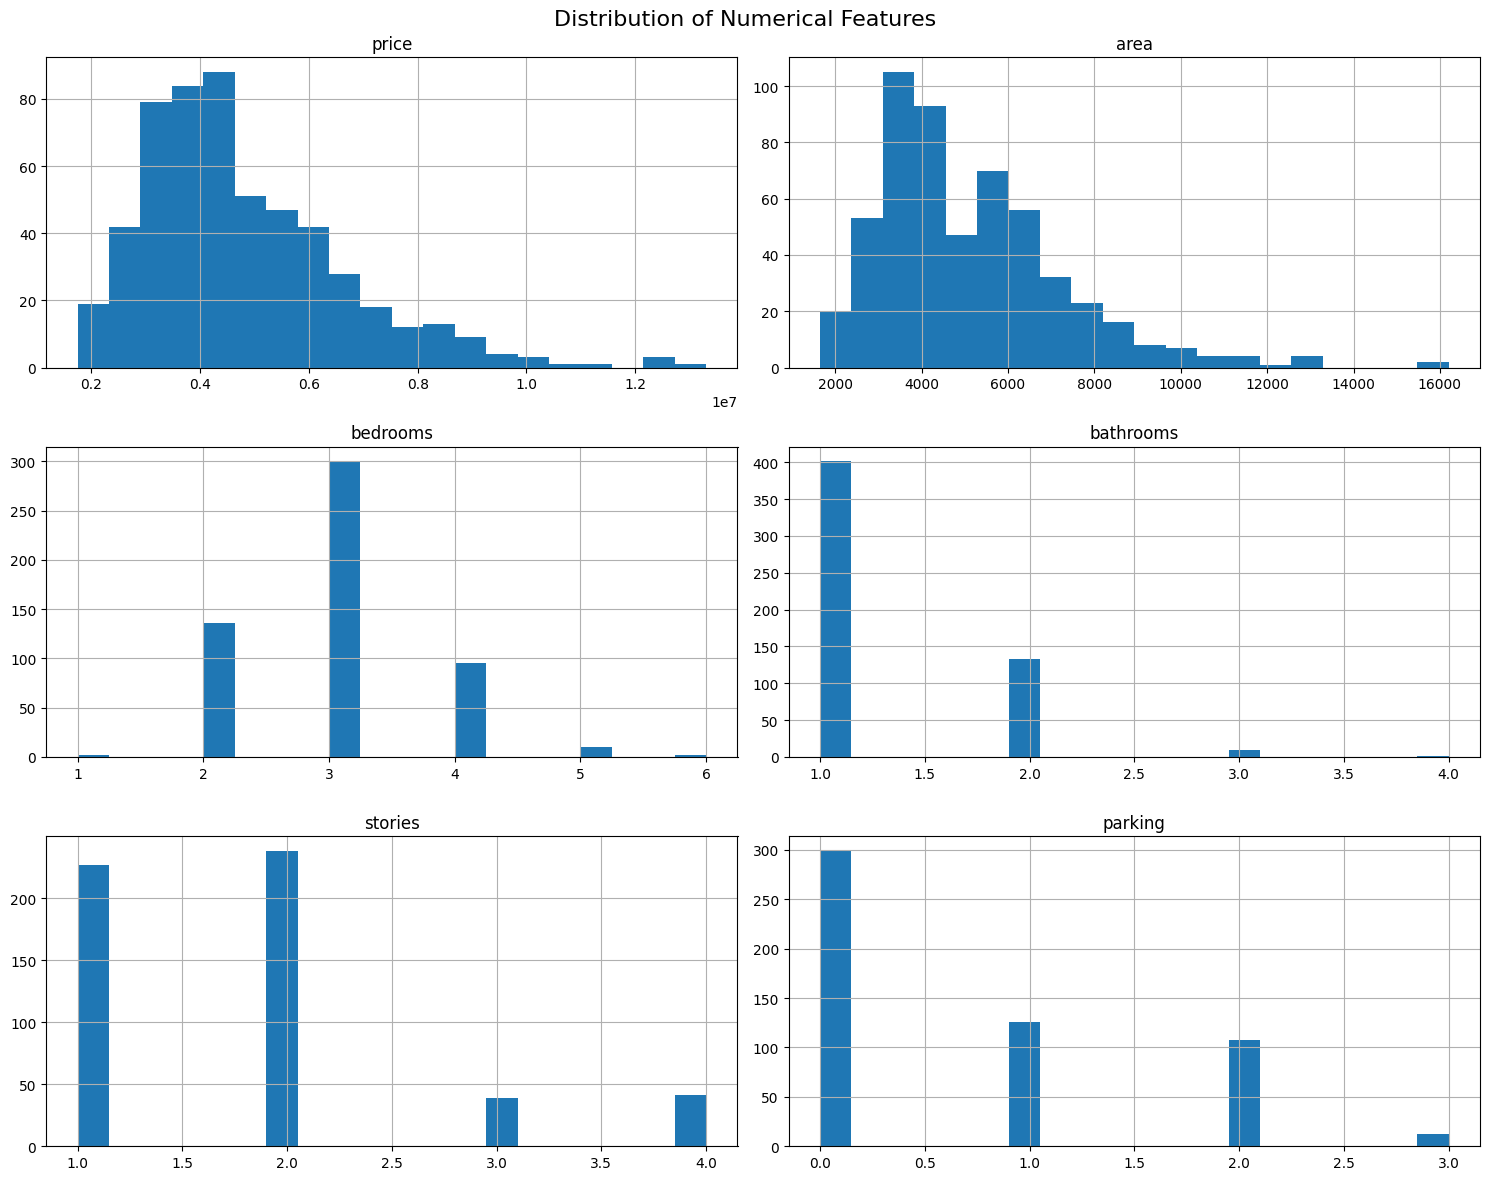

In [80]:
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

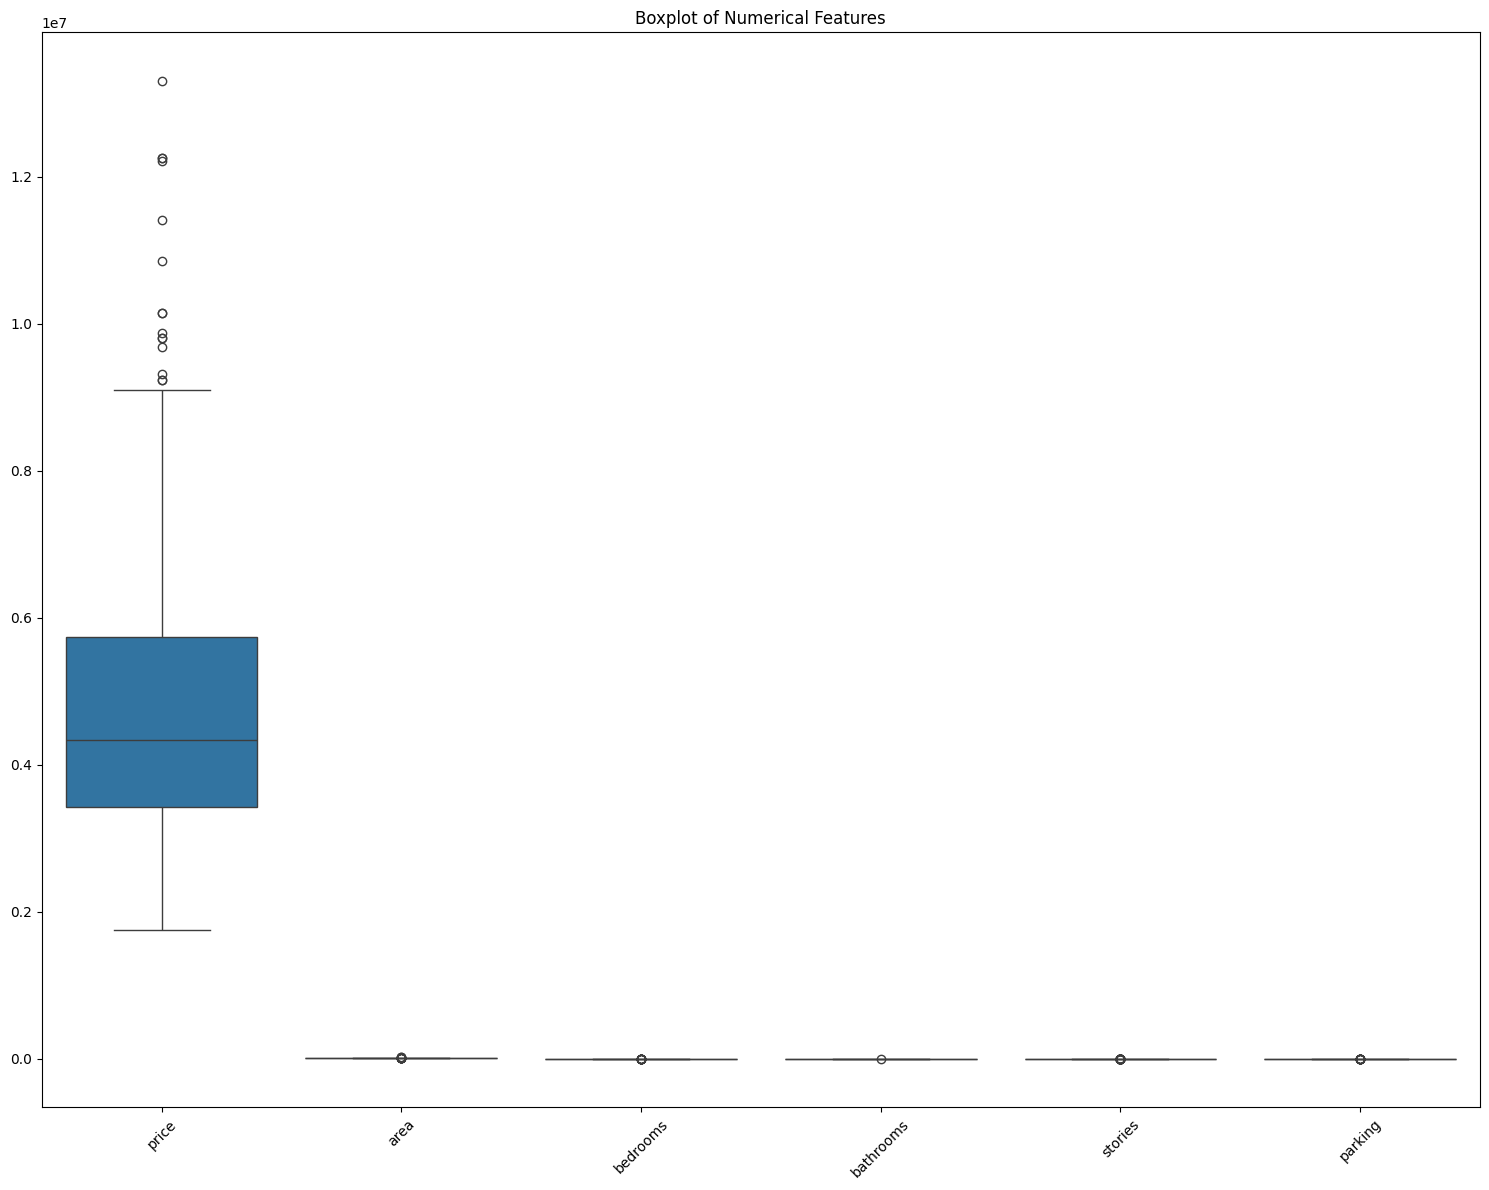

In [81]:
plt.figure(figsize=(15, 12))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Task 2**

In [82]:
print("Missing values before preprocessing:")
print(df.isnull().sum())

Missing values before preprocessing:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [83]:

X = df.drop("price", axis=1)
y = df["price"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus'],
      dtype='object')

Target:
price


In [84]:

categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

Numerical columns:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking']


In [85]:

X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

print("Shape after encoding:", X_encoded.shape)

X_encoded.head()

Shape after encoding: (545, 13)


,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,2,True,False,False,False,True,True,False,False
1,8960,4,4,4,3,True,False,False,False,True,False,False,False
2,9960,3,2,2,2,True,False,True,False,False,True,True,False
3,7500,4,2,2,3,True,False,True,False,True,True,False,False
4,7420,4,1,2,2,True,True,True,False,True,False,False,False


In [86]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_encoded)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X_encoded.columns,
    index=X_encoded.index
)

X_scaled.head()

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,1.046726,1.403419,1.421812,1.378217,1.517692,0.405623,-0.465315,-0.734539,-0.219265,1.472618,1.804941,-0.844888,-0.696429
1,1.757010,1.403419,5.405809,2.532024,2.679409,0.405623,-0.465315,-0.734539,-0.219265,1.472618,-0.554035,-0.844888,-0.696429
2,2.218232,0.047278,1.421812,0.224410,1.517692,0.405623,-0.465315,1.361397,-0.219265,-0.679063,1.804941,1.183588,-0.696429
3,1.083624,1.403419,1.421812,0.224410,2.679409,0.405623,-0.465315,1.361397,-0.219265,1.472618,1.804941,-0.844888,-0.696429
4,1.046726,1.403419,-0.570187,0.224410,1.517692,0.405623,2.149083,1.361397,-0.219265,1.472618,-0.554035,-0.844888,-0.696429


In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.30,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (381, 13)
Testing data: (164, 13)


In [88]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (381, 13)
X_test : (164, 13)
y_train: (381,)
y_test : (164,)


## Task **3**

In [89]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [90]:
#In Using the Simple Linear Regression

X = df[['area']]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Simple Linear Regression")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Simple Linear Regression
MAE: 1387227.8956867643
RMSE: 1787173.725119531
R2 Score: 0.2583140345296001


In [91]:
#In Using Multiple Linear Regression

model2 = LinearRegression()

model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

mae2 = mean_absolute_error(y_test, y_pred2)
rmse2 = np.sqrt(mean_squared_error(y_test, y_pred2))
r2_2 = r2_score(y_test, y_pred2)

print("Multiple Linear Regression")
print("MAE:", mae2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)

Multiple Linear Regression
MAE: 1387227.8956867643
RMSE: 1787173.725119531
R2 Score: 0.2583140345296001


In [92]:
#Both are compare
output = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [mae, mae2],
    'RMSE': [rmse, rmse2],
    'R2 Score': [r2, r2_2]
})

output

,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,1.387228e+06,1.787174e+06,0.258314
1,Multiple Linear Regression,1.387228e+06,1.787174e+06,0.258314


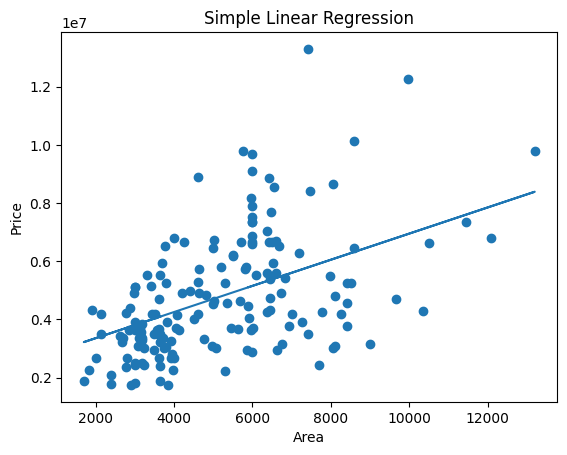

In [93]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Simple Linear Regression")
plt.show()

## **Task 4**

In [94]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Polynomial Regression

X = df[['area']]
y = df['price']

X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X, y, test_size=0.30, random_state=42
)

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_poly)
X_test_poly = poly.transform(X_test_poly)

poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train_poly)

poly_pred = poly_model.predict(X_test_poly)

poly_mae = mean_absolute_error(y_test_poly, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test_poly, poly_pred))
poly_r2 = r2_score(y_test_poly, poly_pred)

print("Polynomial Regression")
print("MAE:", poly_mae)
print("RMSE:", poly_rmse)
print("R2 Score:", poly_r2)

Polynomial Regression
MAE: 1358670.7022353415
RMSE: 1770816.8693347357
R2 Score: 0.2718282593578317


In [95]:
from sklearn.linear_model import Ridge

# In Using Ridge Regression

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression
MAE: 1387227.8957187007
RMSE: 1787173.725146794
R2 Score: 0.25831403450697155


In [96]:
from sklearn.linear_model import Lasso

# In Using Lasso Regression

lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)

Lasso Regression
MAE: 1387227.8957138371
RMSE: 1787173.7251426422
R2 Score: 0.2583140345104177


In [97]:
# Both Three are Comparison
comparison_task4 = pd.DataFrame({
    'Model': [ 'Polynomial Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],
    'MAE': [
        poly_mae,
        ridge_mae,
        lasso_mae
    ],
    'RMSE': [
        poly_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    'R2 Score': [
        poly_r2,
        ridge_r2,
        lasso_r2
    ]
})

comparison_task4

,Model,MAE,RMSE,R2 Score
0,Polynomial Regression,1.358671e+06,1.770817e+06,0.271828
1,Ridge Regression,1.387228e+06,1.787174e+06,0.258314
2,Lasso Regression,1.387228e+06,1.787174e+06,0.258314


Regularization helps to control the complexity of a regression model and reduces the chance of overfitting. Ridge Regression reduces the values of the model coefficients, while Lasso Regression can also make some coefficients zero. This helps the model focus on the more important features. The performance of Ridge and Lasso can be compared using MAE, RMSE, and R² Score. Lower MAE and RMSE indicate better performance, while a higher R² Score indicates better performance. The effect of regularization depends on the dataset and the value of the regularization parameter(α)

In [98]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

svr_model = SVR(kernel='rbf')

svr_model.fit(X_train, y_train)

svr_pred = svr_model.predict(X_test)

svr_mae = mean_absolute_error(y_test, svr_pred)
svr_mse = mean_squared_error(y_test, svr_pred)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, svr_pred)

print("Support Vector Regression")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R2 Score:", svr_r2)

Support Vector Regression
MAE: 1578093.106071879
MSE: 4462116245725.625
RMSE: 2112372.1844707257
R2 Score: -0.036161376445002835


In [99]:
# Final comparison of all regression models
y = df["price"]
X_simple = df[["area"]]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.30, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

simple_pred = simple_model.predict(X_test_s)



X = df.drop("price", axis=1)

# Convert categorical columns into numbers
X = pd.get_dummies(X, drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_pred = multiple_model.predict(X_test)


X_poly = df[["area"]]

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly, y, test_size=0.30, random_state=42
)

poly = PolynomialFeatures(degree=2)

X_train_p = poly.fit_transform(X_train_p)
X_test_p = poly.transform(X_test_p)

poly_model = LinearRegression()
poly_model.fit(X_train_p, y_train_p)

poly_pred = poly_model.predict(X_test_p)


ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)


lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

svr_model = SVR(kernel="rbf")
svr_model.fit(X_train, y_train)

svr_pred = svr_model.predict(X_test)

predictions = [
    (y_test_s, simple_pred),
    (y_test, multiple_pred),
    (y_test_p, poly_pred),
    (y_test, ridge_pred),
    (y_test, lasso_pred),
    (y_test, svr_pred)
]

model_names = [
    "Simple Linear Regression",
    "Multiple Linear Regression",
    "Polynomial Regression",
    "Ridge Regression",
    "Lasso Regression",
    "SVR"
]

results = []

for name, (actual, predicted) in zip(model_names, predictions):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    results.append([name, mae, mse, rmse, r2])


All_comparison = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

print("Final Model Comparison")
All_comparison

Final Model Comparison


,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,1.387228e+06,3.193990e+12,1.787174e+06,0.258314
1,Multiple Linear Regression,9.203929e+05,1.523019e+12,1.234107e+06,0.646335
2,Polynomial Regression,1.358671e+06,3.135792e+12,1.770817e+06,0.271828
3,Ridge Regression,9.201706e+05,1.522881e+12,1.234051e+06,0.646367
4,Lasso Regression,9.203928e+05,1.523020e+12,1.234107e+06,0.646335
5,SVR,1.578105e+06,4.462186e+12,2.112389e+06,-0.036178


# **Observation**
1. Multiple Linear Regression, Ridge Regression, and Lasso      Regression gave better results than Simple and Polynomial  Regression.
2. Ridge Regression gave the highest R² Score (0.6464) among the models.
3.Ridge Regression also had a low MAE and RMSE, showing smaller prediction errors.
4. Simple Linear Regression had an R² Score of about 0.2583.
Polynomial Regression had an R² Score of about 0.2718.
SVR performed poorly on this dataset and gave a negative R² Score.

4. Simple Linear Regression had an R² Score of about 0.2583.
Polynomial Regression had an R² Score of about 0.2718.
SVR performed poorly on this dataset and gave a negative R² Score.

In based on obtained result , **Ridge Regression** is recommended as the best-performing model for this house price prediction dataset.
It achieved the highest R² Score (0.6464) among the tested models.
It also showed low MAE and RMSE, indicating comparatively smaller prediction errors.

# **Conclusion**
The House Price Prediction dataset was successfully analyzed and preprocessed using Python. The dataset was checked for missing values, categorical variables were encoded, and numerical features were scaled before splitting the data into training and testing sets. Different regression models, including Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, Lasso Regression, and Support Vector Regression, were implemented. Their performance was compared using MAE, MSE, RMSE, and R² Score. The results showed that Multiple Linear Regression, Ridge Regression, and Lasso Regression performed better than Simple Linear Regression, Polynomial Regression, and SVR. Ridge Regression achieved the highest R² Score of approximately 0.6464, along with low prediction errors. SVR showed comparatively poor performance with a negative R² Score. Overall, the experiment helped in understanding how different regression techniques perform on house price data. Based on the obtained results, Ridge Regression was selected as the recommended model for house price prediction. The experiment also showed that regularization can help control model complexity and improve model performance on the given dataset.